# Escalera de dominio: de las sílabas de laboratorio al juez de pronunciación

Continúa [01_tone_perfect_pipeline.ipynb](01_tone_perfect_pipeline.ipynb). Allí los modelos llegan al 98,8–99,0 % con seis nativos que leen sílabas aisladas en estudio, una cifra que no dice cuánto valen en habla real ni si sirven para corregir a un alumno. Este notebook sube esa escalera paso a paso:

1. **Peldaño 1: habla continua de nativos (AISHELL-3).** ¿Cuánto cae el modelo de la app y por qué?
2. **Contexto y modelos preentrenados.** ¿Se recupera con contexto de frase o con HuBERT?
3. **Dos contrafactuales.** ¿Los modelos deciden por el tono que oyen o por la palabra que reconocen?
4. **De los resultados a la app.** La demo «¿Quién te corrige?», la pestaña de resultados y la guía tarareada.

El peldaño 2 (hispanohablantes) depende de las grabaciones y está pendiente.

Igual que el 01, el notebook **no vuelve a ejecutar los pasos pesados** (F0 de 17.549 frases, embeddings, entrenamientos, resíntesis). Lee lo que dejan los scripts en `data/` y `outputs/`. Para regenerarlo todo (requiere el alineamiento de AISHELL-3 de los scripts 09-12 y el pipeline de Tone Perfect del 01):

```powershell
uv run python scripts/15_contornos_aishell3.py
uv run python scripts/16_embeddings_aishell3.py
uv run python scripts/29_escalera_dominio_aishell3.py
uv run python scripts/37_curva_hablantes_aishell3.py
uv run python scripts/30_contexto_f0_aishell3.py
uv run python scripts/31_hubert_aishell3.py
uv run python scripts/32_comparar_contexto_aishell3.py
uv run python scripts/33_contrafactual_f0_plano.py
uv run python scripts/34_contrafactual_cambio_tono.py
# semillas 1 y 2 de 29, 30 y 34 con --train-seed y --out outputs/escalera_dominio/semillas/<carpeta>/semilla_<n>
uv run python scripts/39_resumir_semillas.py
uv run python scripts/35_preparar_laboratorio.py
uv run python scripts/36_exportar_resultados.py
uv run python scripts/06_exportar_guia_tonos.py
```

Los entrenamientos de los scripts 29, 30 y 34 se repitieron con **tres semillas de entrenamiento** (mismos folds y datos, otra inicialización; script 39): las cifras se mueven en milésimas y el orden de los jueces no cambia (sección 7.1). El resto de experimentos usa una semilla.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
OUT, DATA = ROOT / "outputs" / "escalera_dominio", ROOT / "data"
TONES = [1, 2, 3, 4]
pd.set_option("display.precision", 3)


def show(path, width=420):
    display(Image(filename=str(path), width=width))


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

## 1. Por qué una escalera

Un 0,988 con hablante no visto en Tone Perfect solo dice que el modelo distingue cuatro formas de contorno muy marcadas, producidas con cuidado y aisladas. En una app real hay dos saltos: el habla deja de ser de laboratorio y quien habla deja de ser nativo. Mezclarlos impide saber qué rompe qué, así que se miden por separado. El primer peldaño cambia solo el estilo de habla (habla continua leída por nativos) y mantiene a hablantes que pronuncian bien. Así cualquier caída se debe al dominio y no a errores de pronunciación.

## 2. El mismo pipeline sobre AISHELL-3

Para atribuir la caída al dominio, la entrada del modelo tiene que construirse **exactamente igual** en los dos corpus (`15_contornos_aishell3.py`):

- **Sílabas del alineamiento de AISHELL-3 (scripts 09-12).** 40 hablantes (20 mujeres y 20 hombres) alineados con MMS_FA y `fill_gaps` (ver `docs/corpus-bisilabos.md`). Las etiquetas son tonos *realizados*, con el sandhi incluido.
- **F0 con Praat sobre la frase completa** y después cortado por sílaba. Praat necesita contexto en los bordes; cortar antes estropearía el principio y el final de cada sílaba, que es justo donde está el movimiento tonal.
- **Rango por hablante en dos pasadas, `fix_octave_jumps` por sílaba, semitonos respecto a la media del hablante y 64 puntos**, como en Tone Perfect.
- **Un error que habría invalidado todo.** Praat no empieza sus frames en t = 0 sino a media ventana del inicio, y la ventana depende del suelo de F0. Sin corregirlo, los tiempos del alineamiento caían 2-3 frames desplazados sobre el F0, del orden del 10 % de una sílaba de 220 ms. `f0_on_frame_grid` coloca el F0 en la rejilla de 10 ms que empieza en t = 0.

Hay una diferencia que no se puede evitar: la referencia del hablante sale de su habla natural, con la distribución de tonos del chino, y no del 25 % por tono de Tone Perfect.

202975 sílabas alineadas de 40 hablantes y 17549 frases; sin F0 suficiente: 1.1%
sílabas por tono (5 = neutro): {1: 42501, 2: 48089, 3: 32428, 4: 67474, 5: 12483}
T1: recorrido (máx - mín) Tone Perfect 0.7 st | AISHELL-3 0.7 st


T2: recorrido (máx - mín) Tone Perfect 6.7 st | AISHELL-3 1.0 st
T3: recorrido (máx - mín) Tone Perfect 5.7 st | AISHELL-3 3.1 st
T4: recorrido (máx - mín) Tone Perfect 10.7 st | AISHELL-3 2.8 st


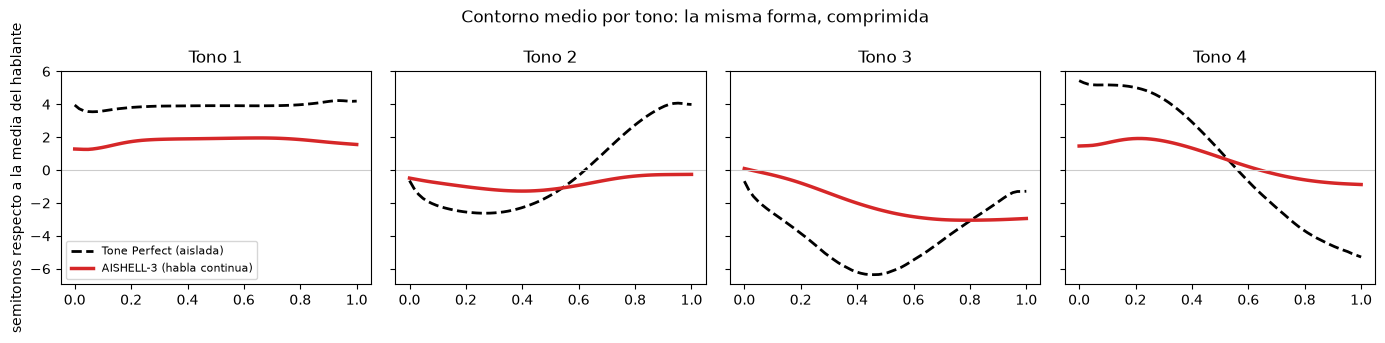

In [2]:
syllables = pd.read_parquet(DATA / "processed" / "silabas_aishell3_praat.parquet")
contours_ai = np.load(DATA / "processed" / "contornos_aishell3_praat.npz")["contours"]
tp = np.load(DATA / "processed" / "contornos_toneperfect_praat.npz", allow_pickle=True)
contours_tp, tones_tp = tp["contours"], tp["tone"].astype(int)

no_f0 = np.isnan(contours_ai).all(axis=1)
print(f"{len(syllables)} sílabas alineadas de {syllables.speaker.nunique()} hablantes y "
      f"{syllables.utt.nunique()} frases; sin F0 suficiente: {no_f0.mean():.1%}")
print("sílabas por tono (5 = neutro):", syllables.tone.value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
t = np.linspace(0, 1, contours_ai.shape[1])
for tone, ax in zip(TONES, axes):
    ax.plot(t, np.nanmean(contours_tp[tones_tp == tone], axis=0), "k--", lw=2, label="Tone Perfect (aislada)")
    ax.plot(t, np.nanmean(contours_ai[syllables.tone.to_numpy() == tone], axis=0), color="tab:red", lw=2.5,
            label="AISHELL-3 (habla continua)")
    ax.axhline(0, color="0.8", lw=0.8)
    ax.set_title(f"Tono {tone}")
axes[0].set_ylabel("semitonos respecto a la media del hablante")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Contorno medio por tono: la misma forma, comprimida")
fig.tight_layout()

for tone in TONES:
    a = np.nanmean(contours_tp[tones_tp == tone], axis=0)
    b = np.nanmean(contours_ai[syllables.tone.to_numpy() == tone], axis=0)
    print(f"T{tone}: recorrido (máx - mín) Tone Perfect {a.max() - a.min():.1f} st | AISHELL-3 {b.max() - b.min():.1f} st")

La figura resume el problema antes de entrenar nada. En habla continua las formas se mantienen, pero muy comprimidas: el recorrido del T4 pasa de 10,7 a 2,8 st y el del T2 de 6,7 a 1,0 st (apenas sube), y el T3 pierde la subida final y se queda en un tono bajo descendente (el «medio tercer tono» de los manuales). Un modelo que aprendió las formas exageradas de las sílabas aisladas va a confundir sobre todo lo que se ha aplanado.

## 3. Peldaño 1: el modelo de la app en habla continua

`29_escalera_dominio_aishell3.py` evalúa la misma CNN sobre las 188.743 sílabas de tono pleno con contorno. Quedan fuera las neutras, porque el modelo no las conoce, y el 1 % sin F0. Hay tres condiciones:

- **Cero disparos:** el modelo de la app tal cual, con su temperatura de Tone Perfect.
- **En dominio, completo:** la misma arquitectura entrenada con AISHELL-3, en 5 folds por hablante equilibrados por género.
- **En dominio, tamaño de Tone Perfect:** igual, pero con solo 9.839 sílabas de entrenamiento. Es el control que haría cualquier revisor: AISHELL-3 tiene 14 veces más datos, y sin él no se sabría si la mejora en dominio viene del dominio o del volumen.

La calibración se mide con la temperatura de Tone Perfect (lo que haría la app) y con una temperatura reajustada en AISHELL-3 para cada fold usando solo los demás folds.

In [3]:
rung = load_json(OUT / "aishell3" / "metrics.json")
rows = {"Tone Perfect, hablante no visto (peldaño 0)": {"accuracy": rung["peldano_0_tone_perfect_hablante_no_visto"]}}
labels = {"cero_disparos": "AISHELL-3, cero disparos (T de Tone Perfect)",
          "cero_disparos_T_reajustada": "AISHELL-3, cero disparos (T reajustada)",
          "en_dominio_tamano_tp": "AISHELL-3, en dominio, tamaño de Tone Perfect",
          "en_dominio_completo": "AISHELL-3, en dominio, completo"}
for key, label in labels.items():
    r = rung["condiciones"][key]
    rows[label] = {"accuracy": r["global"]["accuracy"], "media entre hablantes": r["accuracy_hablante_media_std"][0],
                   "desv. entre hablantes": r["accuracy_hablante_media_std"][1], "macro-F1": r["global"]["macro_f1"],
                   "ECE": r["ece"], **{f"recall T{t}": r["global"]["recall_por_tono"][str(t)] for t in TONES}}
pd.DataFrame(rows).T

,accuracy,media entre hablantes,desv. entre hablantes,macro-F1,ECE,recall T1,recall T2,recall T3,recall T4
"Tone Perfect, hablante no visto (peldaño 0)",0.988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"AISHELL-3, cero disparos (T de Tone Perfect)",0.566,0.566,0.069,0.529,0.322,0.734,0.186,0.702,0.667
"AISHELL-3, cero disparos (T reajustada)",0.566,0.566,0.069,0.529,0.017,0.734,0.186,0.702,0.667
"AISHELL-3, en dominio, tamaño de Tone Perfect",0.748,0.748,0.064,0.731,0.007,0.760,0.760,0.606,0.798
"AISHELL-3, en dominio, completo",0.768,0.768,0.063,0.751,0.006,0.783,0.772,0.627,0.822


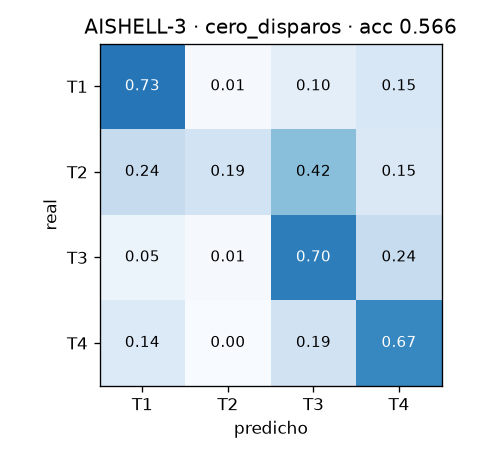

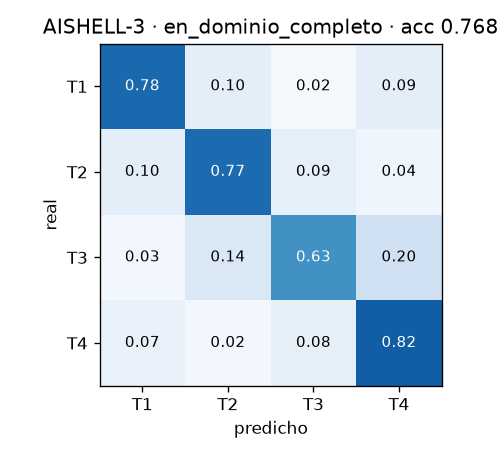

In [4]:
for name in ["cero_disparos", "en_dominio_completo"]:
    show(OUT / "aishell3" / f"confusion_{name}.png", width=380)

Hay tres lecturas, de más a menos evidente:

1. **El 98,8 % se queda en 56,6 %.** El tono que más sufre es el T2 (recall 0,19): comprimido, su subida no se distingue de un T1 o de un T3.
2. **El modelo se equivoca con seguridad.** Con la temperatura de Tone Perfect, el ECE es 0,32: de media, su confianza se aleja 32 puntos de lo que acierta, casi siempre por exceso. En una app eso significa decirle a un alumno, con total confianza, que lo ha hecho mal cuando no es así. Reajustar la temperatura lo deja en 0,017, así que **la calibración no viaja entre dominios y hay que rehacerla en cada uno**.
3. **Más sílabas no es la solución.** Entrenar en el dominio recupera 18 puntos (0,748 con el tamaño de Tone Perfect), y multiplicar las sílabas por 14 con los mismos hablantes solo añade 2 más (0,768). La sección 3.1 mira la otra variable, el número de voces.

### 3.1 ¿Y más voces?

`37_curva_hablantes_aishell3.py` entrena con 4, 8, 16 y 32 hablantes de los otros folds (mitad mujeres, mitad hombres, con todas sus sílabas) y evalúa en los hablantes del fold. Los subconjuntos son anidados, para que la diferencia entre dos puntos no dependa de qué hablantes tocan. Entrena dos modelos: la CNN por sílaba de la sección 3 y la CNN + BiGRU sobre la frase de la sección 4, que se adelanta aquí.

accuracy_media        accuracy_desv       
modelo        cnn_silaba  frase    cnn_silaba  frase
hablantes                                           
4                  0.730  0.772         0.015  0.020
8                  0.745  0.797         0.015  0.016
16                 0.756  0.812         0.015  0.013
32                 0.768  0.833         0.014  0.010

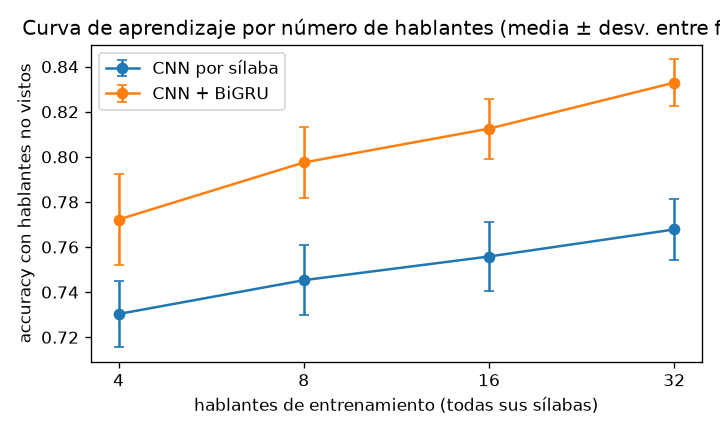

Control del script 29 (32 hablantes, sílabas recortadas al tamaño de Tone Perfect): 0.748


In [5]:
curve = pd.read_csv(OUT / "curva_hablantes" / "resumen.csv")
display(curve.pivot(index="hablantes", columns="modelo", values=["accuracy_media", "accuracy_desv"]))
show(OUT / "curva_hablantes" / "curva_hablantes.png", width=520)
domain = load_json(OUT / "aishell3" / "metrics.json")["condiciones"]
print(f"Control del script 29 (32 hablantes, sílabas recortadas al tamaño de Tone Perfect): "
      f"{domain['en_dominio_tamano_tp']['global']['accuracy']:.3f}")

La curva no se aplana en el rango medido. Cada vez que se duplican los hablantes, la CNN por sílaba gana entre 1,1 y 1,5 puntos (0,730 / 0,745 / 0,756 / 0,768) y la frase entre 1,5 y 2,5 (0,772 / 0,797 / 0,812 / 0,833). La desviación entre folds es de 1-2 puntos, del mismo orden que cada salto, así que un punto aislado no es concluyente, pero la tendencia sí, porque se repite en los cinco folds y en los dos modelos.

Más hablantes también trae más sílabas (de 18.000 a 151.000), así que la curva sola no separa voces de volumen. El control del script 29 sí ayuda a separarlos. Con 32 hablantes y solo 9.839 sílabas se llega a 0,748, más que con 4 hablantes y 18.000 sílabas (0,730). **Con menos sílabas pero más voces se acierta más**: lo que generaliza a un hablante nuevo es la variedad de voces, no la cantidad de sílabas de las mismas voces.

Esto matiza la conclusión de la sección 3. El techo de ~0,77 de la CNN por sílaba no es de volumen de sílabas, pero sí podría subir algo con más voces, al ritmo de ~1,2 puntos por duplicación. Para llegar a lo que logra la frase completa (0,833) harían falta unas 5 duplicaciones más, unas 40 veces más hablantes, si la tendencia se mantuviera, cosa que no se ha medido. El contexto sigue siendo la palanca grande. La curva de la frase es más empinada, así que el modelo con contexto aprovecha mejor cada voz nueva.

### 3.2 Dónde falla

In [6]:
breakdown = pd.read_csv(OUT / "aishell3" / "desglose.csv")
columns = ["n", "cero_disparos", "en_dominio_completo"]
for factor in ["tono", "duracion_ms", "posicion_en_frase", "tono_siguiente"]:
    display(breakdown[breakdown.factor == factor].set_index("nivel")[columns].rename_axis(factor))

,n,cero_disparos,en_dominio_completo
tono,,,
T1,42432,0.734,0.783
T2,47774,0.186,0.772
T3,31530,0.702,0.627
T4,67007,0.667,0.822


,n,cero_disparos,en_dominio_completo
duracion_ms,,,
"(181.0, 221.0]",47175,0.565,0.769
"(221.0, 261.0]",47185,0.600,0.811
"(261.0, 2292.0]",47186,0.608,0.822
"(59.0, 181.0]",47197,0.491,0.671


,n,cero_disparos,en_dominio_completo
posicion_en_frase,,,
final,63423,0.509,0.721
inicio,57808,0.594,0.781
medio,67512,0.596,0.802


,n,cero_disparos,en_dominio_completo
tono_siguiente,,,
T1,35308,0.582,0.770
T2,41045,0.613,0.787
T3,27824,0.547,0.827
T4,58664,0.581,0.767
neutro,12053,0.515,0.723
ninguno,13849,0.408,0.634


Incluso entrenado en el dominio, el modelo falla más en la **última sílaba de la frase** (0,63 sin sílaba siguiente), en las **sílabas cortas** (0,67 por debajo de 181 ms) y en el **T3** (0,63). Son los tres sitios donde el contexto ayuda a un oyente humano: al final de la frase la declinación y la voz rasposa deforman el contorno, en una sílaba corta apenas hay contorno, y el T3 realizado depende de lo que viene detrás. Eso lleva directamente al siguiente experimento.

## 4. Contexto sobre el F0

`30_contexto_f0_aishell3.py` mantiene la entrada (solo F0) y amplía lo que ve el modelo. Usa las mismas sílabas evaluadas, los mismos folds y la misma calibración sin fuga que el script 29:

- **Ventana ±1:** la CNN recibe 9 canales: contorno, derivada y un canal de presencia de la sílaba anterior, la actual y la siguiente. El canal de presencia distingue un borde de frase o una sílaba sin F0 de un contorno plano a cero.
- **Frase (CNN + BiGRU):** la misma CNN codifica cada sílaba y una BiGRU de dos capas recorre la frase entera. Así cada predicción puede usar la declinación, el sandhi y la coarticulación con cualquier vecina. Las sílabas neutras y sin F0 entran como contexto pero no cuentan en la pérdida. Solo se codifican las sílabas reales y no el relleno, para que BatchNorm no vea ceros artificiales.

Ninguno de los dos ve la duración, igual que la CNN por sílaba.

In [7]:
context = load_json(OUT / "aishell3_contexto" / "metrics.json")
pd.DataFrame({name: {"accuracy": r["global"]["accuracy"], "media entre hablantes": r["accuracy_hablante_media_std"][0],
                     "macro-F1": r["global"]["macro_f1"], "ECE": r["ece"],
                     **{f"recall T{t}": r["global"]["recall_por_tono"][str(t)] for t in TONES}}
              for name, r in context["modelos"].items()}).T

,accuracy,media entre hablantes,macro-F1,ECE,recall T1,recall T2,recall T3,recall T4
ventana,0.813,0.813,0.802,0.006,0.831,0.808,0.724,0.846
frase,0.833,0.833,0.825,0.005,0.841,0.825,0.776,0.860


El contexto ayuda y la ayuda va donde hacía falta. La frase completa sube a 0,833, con el T3 de 0,63 a 0,78, las sílabas cortas de 0,67 a 0,76 y la última de la frase de 0,63 a 0,77 (desglose en la sección 5). Sigue lejos del 98,8 % de laboratorio.

## 5. HuBERT y una línea base que no oye nada

`16_embeddings_aishell3.py` pasa cada frase **completa** por `chinese-hubert-base`, el mismo modelo y commit que en el 01, y promedia cada capa dentro de los tiempos de cada sílaba. Por la autoatención, cada sílaba lleva ya información de toda la frase, así que es un modelo con contexto, comparable a la BiGRU. `31_hubert_aishell3.py` entrena una regresión logística por capa y elige la capa dentro de cada fold, por validación interna sobre los demás folds.

Con 150.000 filas por 768 dimensiones y 325 ajustes, la regresión logística de sklearn era inviable, así que se reimplementó en GPU (`tonos.linear_probe`: mismo objetivo, L-BFGS). Con 300 iteraciones la capa 0, mal condicionada, tardaba unos 20 minutos por capa; con 100 iteraciones la accuracy es la misma (0,9598 frente a 0,9594 en una prueba) y cada ajuste tarda unos 2 s.

capa elegida por fold: {'0': 10, '1': 10, '2': 10, '3': 10, '4': 10}


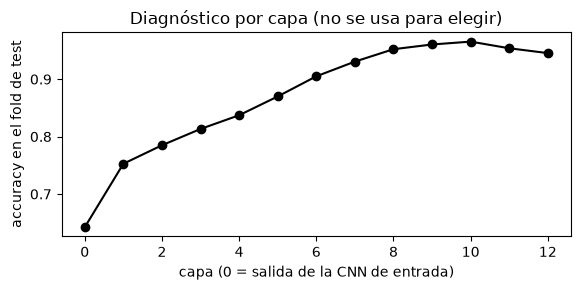

In [8]:
hubert = load_json(OUT / "aishell3_hubert" / "metrics.json")
layers = pd.read_csv(OUT / "aishell3_hubert" / "accuracy_por_capa.csv", index_col=0).accuracy
print("capa elegida por fold:", hubert["capa_elegida_por_fold"])
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(layers.index, layers.values, "o-", color="k")
ax.set_xlabel("capa (0 = salida de la CNN de entrada)")
ax.set_ylabel("accuracy en el fold de test")
ax.set_title("Diagnóstico por capa (no se usa para elegir)")
fig.tight_layout()

Con la capa 10, elegida en los cinco folds, HuBERT llega a **0,966**. Antes de creérselo hace falta una comparación que el resto de la literatura suele omitir. HuBERT codifica sobre todo **qué se dice**, y en chino el carácter casi determina el tono. Así que `32_comparar_contexto_aishell3.py` añade una **línea base léxica sin audio**: el tono más frecuente de cada carácter en los folds de entrenamiento (si el carácter no aparece, el de la sílaba sin tono).

Todas las diferencias llevan intervalos de confianza al 95 % por **bootstrap de hablantes**. La unidad independiente es el hablante, no la sílaba: remuestrear 188.743 sílabas daría intervalos falsamente estrechos. Las diferencias son pareadas, con los mismos hablantes en cada remuestreo.

In [9]:
pd.read_csv(OUT / "comparacion_contexto" / "comparacion.csv").set_index("modelo")

,accuracy,ic95_inf,ic95_sup,dif_vs_cnn_silaba,dif_ic95_inf,dif_ic95_sup
modelo,,,,,,
lexico_sin_audio,0.934,0.929,0.939,0.166,0.148,0.186
cero_disparos_tone_perfect,0.566,0.544,0.588,-0.202,-0.213,-0.192
cnn_silaba,0.768,0.747,0.787,0.000,0.000,0.000
ventana,0.813,0.794,0.830,0.044,0.040,0.049
frase,0.833,0.815,0.850,0.065,0.059,0.070
hubert,0.966,0.960,0.970,0.197,0.182,0.214
frase_mas_hubert,0.961,0.955,0.967,0.193,0.178,0.209


In [10]:
print("Solapamiento de errores frase / HuBERT:", load_json(OUT / "comparacion_contexto" / "solapamiento_errores.json"))
context_breakdown = pd.read_csv(OUT / "comparacion_contexto" / "desglose.csv")
models = ["lexico_sin_audio", "cnn_silaba", "frase", "hubert"]
for factor in ["tono", "duracion_ms", "tono_siguiente"]:
    display(context_breakdown[context_breakdown.factor == factor].set_index("nivel")[["n", *models]].rename_axis(factor))

Solapamiento de errores frase / HuBERT: {'errores_frase': 31559, 'errores_hubert': 6518, 'errores_comunes': 3990, 'accuracy_oraculo': 0.9789}


,n,lexico_sin_audio,cnn_silaba,frase,hubert
tono,,,,,
T1,42432,0.979,0.783,0.841,0.965
T2,47774,0.840,0.772,0.825,0.959
T3,31530,0.954,0.627,0.776,0.952
T4,67007,0.964,0.822,0.860,0.977


,n,lexico_sin_audio,cnn_silaba,frase,hubert
duracion_ms,,,,,
"(181.0, 221.0]",47175,0.934,0.769,0.839,0.965
"(221.0, 261.0]",47185,0.943,0.811,0.868,0.972
"(261.0, 2292.0]",47186,0.953,0.822,0.867,0.972
"(59.0, 181.0]",47197,0.907,0.671,0.758,0.952


,n,lexico_sin_audio,cnn_silaba,frase,hubert
tono_siguiente,,,,,
T1,35308,0.967,0.770,0.839,0.970
T2,41045,0.955,0.787,0.844,0.965
T3,27824,0.792,0.827,0.857,0.958
T4,58664,0.956,0.767,0.831,0.968
neutro,12053,0.943,0.723,0.804,0.963
ninguno,13849,0.975,0.634,0.765,0.963


**Sin oír nada se acierta el 93,4 %.** HuBERT queda solo 3 puntos por encima del léxico. La combinación frase + HuBERT no mejora a HuBERT solo, aunque sus errores son bastante distintos (un oráculo que eligiera siempre al que acierta llegaría al 97,9 %).

Hay un indicio de que HuBERT oye algo más que el léxico. Donde el léxico falla por el sandhi (T3 ante T3, realizado como T2), HuBERT se mantiene. Pero no basta: la regla del sandhi también se deduce del carácter siguiente, que HuBERT reconoce. La accuracy no puede separar «oye el tono» de «sabe qué palabra es». Hace falta intervenir sobre el audio.

## 6. Contrafactual 1: borrar el tono

`33_contrafactual_f0_plano.py` toma 2.400 frases (60 por hablante) y las resintetiza con WORLD de dos formas:

- **Resíntesis sin tocar el F0:** el control de los artefactos del vocoder.
- **F0 plano:** el F0 de los frames con voz se fija a la media geométrica de la frase. Desaparece toda la información tonal y se conserva el contenido segmental, la duración, la intensidad y la calidad de voz.

Cada frase la clasifica el clasificador de HuBERT del fold que no ha visto a su hablante. La **comprobación de la manipulación** mide con Praat la dispersión del F0 de cada frase en las tres condiciones.

In [11]:
flat = load_json(OUT / "contrafactual_f0_plano" / "metrics.json")
print("dispersión del F0 por frase (st, mediana):", flat["dispersion_f0_st_mediana"])
print("coincidencia de la predicción con el léxico:", flat["coincidencia_con_lexico"])
display(pd.read_csv(OUT / "contrafactual_f0_plano" / "comparacion.csv").set_index("condicion"))
pd.DataFrame(flat["accuracy_por_tono"]).T.rename_axis("tono")

dispersión del F0 por frase (st, mediana): {'original': 2.959, 'resintesis': 2.63, 'f0_plano': 0.122}
coincidencia de la predicción con el léxico: {'original': 0.9138, 'resintesis': 0.9054, 'f0_plano': 0.6712}


,accuracy,ic95_inf,ic95_sup,dif_vs_original,dif_ic95_inf,dif_ic95_sup
condicion,,,,,,
original,0.964,0.959,0.969,0.000,0.000,0.000
resintesis,0.953,0.944,0.960,-0.011,-0.016,-0.006
f0_plano,0.693,0.676,0.710,-0.271,-0.287,-0.254
lexico_sin_audio,0.932,0.927,0.938,-0.031,-0.038,-0.026


,original,resintesis,f0_plano,lexico_sin_audio
tono,,,,
1,0.963,0.955,0.880,0.976
2,0.957,0.940,0.680,0.841
3,0.951,0.934,0.437,0.951
4,0.975,0.969,0.703,0.962


La manipulación funciona: la dispersión del F0 baja de 2,96 a 0,12 st. El vocoder solo cuesta 1,1 puntos. **Con el tono borrado, HuBERT cae 27 puntos, hasta 0,693.** Hay dos conclusiones:

- **HuBERT sí usa el pitch:** 27 puntos dependen de él, así que no es puramente léxico.
- **Sin ningún tono sigue acertando el 69 %.** Parte de eso es léxico. Otra parte son pistas que no son pitch y que WORLD conserva (duración, intensidad, voz rasposa del T3). Y otra es un sesgo: un F0 plano *suena* a T1, por eso el T1 se queda en 0,88 y el T3 cae a 0,44. Este experimento no separa esas tres partes.

Para una app el dato incómodo es el segundo. Un alumno que leyera una frase sin ningún tono recibiría el visto bueno de HuBERT en el 69 % de las sílabas. Pero el F0 plano es un caso extremo. El caso de uso real es más sutil: una frase bien dicha salvo un tono.

## 7. Contrafactual 2: cambiar el tono de una sola sílaba

`34_contrafactual_cambio_tono.py` reproduce el error de un alumno. Usa las mismas 2.400 frases: en cada una se elige una sílaba al azar y se le impone con WORLD el contorno de otro tono, también al azar, sin tocar el resto de la frase. Un buen juez debe **seguir al tono impuesto** y no al que corresponde a la palabra. Las decisiones de diseño:

- **El contorno impuesto es el de una sílaba real de ese tono, de un hablante de otro fold,** y no la media del tono. La primera versión imponía la media, y la prueba de humo (1 época, 80 sílabas, no guardada) dio a la CNN un 96 % de detección. Ese número era sospechoso: la media es un prototipo limpio que favorece a los modelos de F0 frente a la variabilidad del habla real.
- **El audio manipulado pasa por el mismo pipeline de F0 que el de entrenamiento,** con el perfil del hablante (rango y referencia) estimado sobre su audio original, igual que hace la app con la calibración.
- **Los tres modelos se reentrenan por fold** con la misma configuración que en los scripts 29-31, y cada frase la juzga el modelo que no ha visto a su hablante.
- **Comprobación de la manipulación:** distancia del contorno reextraído al impuesto frente a la distancia al de la resíntesis sin cambios.

In [12]:
swap = load_json(OUT / "contrafactual_cambio_tono" / "metrics.json")
print("manipulación:", swap["manipulacion"])
rates = pd.read_csv(OUT / "contrafactual_cambio_tono" / "comparacion.csv")
table = rates.pivot(index="modelo", columns="metrica", values="tasa")[
    ["acierto_original", "acierto_resintesis", "detecta_cambio", "acepta_error"]]
table.loc[["cnn_silaba", "frase", "hubert", "lexico_sin_audio"]]

manipulación: {'rmse_st_a_contorno_impuesto': 0.44338392824620215, 'rmse_st_a_resintesis_sin_cambios': 3.036992259356167, 'silabas_cambiadas_sin_f0': 13}


metrica,acierto_original,acierto_resintesis,detecta_cambio,acepta_error
modelo,,,,
cnn_silaba,0.761,0.740,0.675,0.100
frase,0.833,0.811,0.598,0.142
hubert,0.968,0.958,0.310,0.474
lexico_sin_audio,0.925,0.925,0.022,0.925


In [13]:
display(rates[rates.metrica == "detecta_cambio"].set_index("modelo")[["tasa", "ic95_inf", "ic95_sup"]])
pd.read_csv(OUT / "contrafactual_cambio_tono" / "por_par.csv", index_col=0).rename_axis("original -> impuesto")

,tasa,ic95_inf,ic95_sup
modelo,,,
cnn_silaba,0.675,0.658,0.692
frase,0.598,0.575,0.621
hubert,0.310,0.288,0.330
lexico_sin_audio,0.022,0.016,0.028


,n,cnn_silaba,frase,hubert
original -> impuesto,,,,
T1 -> T2,166,0.687,0.512,0.343
T1 -> T3,194,0.572,0.526,0.263
T1 -> T4,181,0.740,0.696,0.337
T2 -> T1,216,0.741,0.704,0.333
T2 -> T3,191,0.592,0.544,0.204
T2 -> T4,201,0.736,0.647,0.423
T3 -> T1,136,0.713,0.625,0.287
T3 -> T2,146,0.651,0.562,0.267
T3 -> T4,126,0.746,0.548,0.381


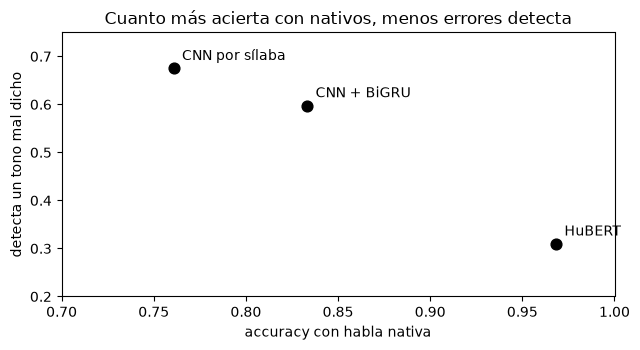

In [14]:
order = ["cnn_silaba", "frase", "hubert"]
names = {"cnn_silaba": "CNN por sílaba", "frase": "CNN + BiGRU", "hubert": "HuBERT"}
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for model in order:
    x, y = table.loc[model, "acierto_original"], table.loc[model, "detecta_cambio"]
    ax.scatter(x, y, s=60, color="k")
    ax.annotate(names[model], (x, y), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("accuracy con habla nativa")
ax.set_ylabel("detecta un tono mal dicho")
ax.set_xlim(0.7, 1.0)
ax.set_ylim(0.2, 0.75)
ax.set_title("Cuanto más acierta con nativos, menos errores detecta")
fig.tight_layout()

**El orden de los modelos se invierte.** La manipulación funciona: el contorno reextraído queda a 0,44 st del impuesto y a 3,04 st del original, y solo 13 sílabas se quedan sin F0.

- **CNN por sílaba:** acierta el 76 % con nativos y detecta el 67,5 % de los cambios. Solo deja pasar el 10 %.
- **CNN + BiGRU:** acierta más (83 %) pero detecta menos (59,8 %) y deja pasar el 14 %. Sobre la misma señal de F0, el contexto aprende qué tono es *probable* ahí, y eso lo sesga hacia lo esperado.
- **HuBERT:** acierta el 97 % pero solo detecta el 31 %, y en el **47 %** de los casos responde con el tono que «toca» según la palabra.
- **Léxico:** por construcción se queda siempre con el tono original (el 2 % restante son sus propios errores).

En todos los pares de tonos, la CNN por sílaba detecta más que la BiGRU y esta más que HuBERT. La debilidad compartida es imponer un T3 (lo comprimido y bajo se confunde fácilmente). Esta es la tesis del trabajo: **en un sistema de corrección, la accuracy sobre habla nativa no mide la validez del juez. Hay que medir si su decisión sigue a la señal que se quiere evaluar.** Para la app, el mejor juez es el más simple, la CNN por sílaba sin contexto, que es la que ya usa. Lo que hay que mejorar es su accuracy en habla continua sin añadirle contexto ni léxico.

### 7.1 ¿Depende de la semilla?

Una crítica obvia a los números de este notebook es que salen de un solo entrenamiento. `29`, `30` y `34` se repitieron con `--train-seed` 1 y 2: mismos folds, mismas frases y mismos contornos donantes, y solo cambian la inicialización y el orden de entrenamiento de las redes. HuBERT no se repite: su clasificador es una regresión logística con L-BFGS, que da lo mismo con cualquier semilla.

In [15]:
seeds = pd.read_csv(OUT / "semillas" / "resumen.csv").set_index("metrica")
display(seeds)
by_seed = pd.read_csv(OUT / "semillas" / "semillas.csv")
detection = by_seed[by_seed.metrica.str.endswith("detecta_cambio")].assign(juez=lambda d: d.metrica.str.split(" · ").str[1])
detection.pivot(index="semilla", columns="juez", values="valor")[["cnn_silaba", "frase", "hubert"]]

,media,sd,minimo,maximo
metrica,,,,
"29 · CNN por sílaba, tamaño de Tone Perfect",0.747,4.000e-04,0.747,0.748
"29 · CNN por sílaba, completo",0.768,1.200e-03,0.767,0.769
30 · ventana ±1,0.812,7.000e-04,0.811,0.813
30 · frase (CNN + BiGRU),0.834,8.000e-04,0.833,0.834
34 · cnn_silaba · detecta_cambio,0.679,3.400e-03,0.675,0.681
34 · cnn_silaba · acepta_error,0.100,1.300e-03,0.099,0.101
34 · cnn_silaba · acierto_original,0.765,4.600e-03,0.761,0.770
34 · frase · detecta_cambio,0.597,1.800e-03,0.595,0.598
34 · frase · acepta_error,0.149,7.100e-03,0.142,0.157


juez,cnn_silaba,frase,hubert
semilla,,,
0,0.675,0.598,0.31
1,0.680,0.595,0.31
2,0.681,0.598,0.31


La desviación entre semillas es de milésimas: 0,001 en la accuracy de la CNN por sílaba y de la frase, y como mucho 0,007 en las tasas del contrafactual (lo que deja pasar la frase). Las diferencias entre jueces son de decenas de puntos, así que el orden CNN > frase > HuBERT en detección se repite en las tres semillas. La semilla no explica ningún resultado de este notebook.

## 8. De los resultados a la app

Los hallazgos se han llevado a dos pestañas nuevas del frontend:

- **«¿Quién te corrige?»** (`src/tonos/lab.py`, `/api/lab/*`, paquete de `35_preparar_laboratorio.py`). Eliges una sílaba de una frase real, le cambias el tono y ves en vivo el veredicto de los cuatro jueces.
  - **Sin trampas:** los modelos se entrenan sin el fold 0 y las 24 frases de la demo salen solo de sus 8 hablantes, elegidas al azar sin mirar qué aciertan los modelos.
  - **Contorno impuesto:** el de la sílaba real de entrenamiento más cercana a la media de cada tono; típico pero natural.
  - **Coste:** un juicio tarda ~0,55 s en CPU. Es opcional en la API porque añade HuBERT (~380 MB) al despliegue.
- **«Resultados»** (`36_exportar_resultados.py`). Página estática con las cifras de esta escalera, leídas de `outputs/` y no copiadas a mano, más 4 ejemplos al azar para escuchar.

En la práctica se añadió además una **guía tarareada** (`06_exportar_guia_tonos.py`, `frontend/src/audio/toneGuide.ts`). Antes de grabar se puede escuchar la melodía del tono objetivo a la altura de la propia voz. Usa el mismo contorno que dibuja la gráfica y la duración mediana de cada tono en Tone Perfect (T1 0,64 s, T2 0,71 s, T3 0,84 s, T4 0,50 s). La duración no entra en el modelo porque no transfiere entre hablantes, pero ayuda a imitar.

Se verificó capturando el audio en Edge y midiendo su F0 con Praat (18 de noviembre, no guardado en `outputs/`): error frente al contorno esperado de 0,02 a 0,66 st. El primer timbre (diente de sierra) sonaba a trompeta y se cambió por armónicos que caen como 1/n², que suenan a «mmm» tarareado. La voz nativa de Tone Perfect está pendiente de confirmar su licencia: no aparece en su web y servir los audios en una app desplegada sería redistribuir el corpus.

In [16]:
guide = load_json(ROOT / "frontend" / "src" / "data" / "tone_guide.json")
print("duración de la guía por tono (s):", {t: g["duration_s"] for t, g in guide.items()})
lab_results = load_json(ROOT / "frontend" / "src" / "data" / "resultados.json")
pd.DataFrame([{"texto": e["frase"], "sílaba": f"{e['silaba']} {e['pinyin']}",
               "cambio": f"T{e['tono_original']} -> T{e['tono_impuesto']}",
               **{v["juez"]: v["tono"] for v in e["veredictos"]}} for e in lab_results["ejemplos"]])

duración de la guía por tono (s): {'1': 0.64, '2': 0.71, '3': 0.84, '4': 0.5}


,texto,sílaba,cambio,cnn_silaba,frase,hubert,lexico
0,系上安全带的模样,系 jì,T4 -> T1,1,4,1,4
1,不是什么大事,事 shì,T4 -> T2,2,2,1,4
2,九千六百八十三点六,六 liù,T4 -> T2,2,1,4,4
3,用户还可以设置狗狗的年龄,置 zhì,T4 -> T3,4,4,4,4


Los cuatro ejemplos de la pestaña Resultados, elegidos al azar con semilla, muestran la variedad real: en uno detectan el cambio la CNN por sílaba y HuBERT, en otro las dos CNN, en otro solo la CNN por sílaba y en el último nadie.

## 9. Decisiones y límites

| Decisión | Motivo | Alternativa descartada |
|---|---|---|
| Medir el cambio de dominio por peldaños (estilo de habla primero, hablantes no nativos después) | Saber qué rompe qué | Saltar directamente a hispanohablantes |
| Mismo pipeline de F0 en los dos corpus, F0 sobre la frase completa y rejilla desde t = 0 | Que la caída no se pueda atribuir a una entrada construida de otra forma; Praat necesita contexto en los bordes | Cortar la sílaba antes de calcular el F0; ignorar el desfase de Praat (2-3 frames) |
| Control en dominio con el tamaño de Tone Perfect | Separar dominio de volumen: los datos aportan 2 puntos | Comparar solo con el modelo entrenado con todo |
| Curva por número de hablantes con subconjuntos anidados (script 37) | Separar voces de sílabas: con más voces se gana más que con más sílabas | Subconjuntos al azar en cada punto (la diferencia dependería de qué hablantes tocan) |
| Temperatura reajustada por fold sin fuga | La calibración no viaja: ECE 0,32 → 0,017 | Reutilizar la temperatura de Tone Perfect |
| IC por bootstrap de hablantes, pareados | La unidad independiente es el hablante | Bootstrap de sílabas (intervalos falsamente estrechos) |
| Línea base léxica sin audio | Es el atajo que un modelo de habla puede explotar | Comparar modelos solo entre sí |
| Regresión logística de HuBERT en GPU (L-BFGS, 100 iteraciones) | 325 ajustes viables; misma accuracy que con 300 | sklearn (horas) |
| Contrafactuales con control de resíntesis y comprobación de la manipulación | Separar el efecto de la manipulación de los artefactos de WORLD y verificar que se hizo | Fiarse de que la resíntesis cambia lo que se pretende |
| Contorno impuesto de una sílaba real de otro fold | La media del tono es un prototipo que infla la detección de los modelos de F0 | Imponer la media del tono |
| La CNN por sílaba sigue siendo el juez de la app | Es la que más errores detecta (67,5 %) y la que menos deja pasar (10 %) | HuBERT (97 % con nativos, pero deja pasar el 47 % de los errores) |

**Límites:**
- **Semillas:** tres semillas de entrenamiento en 29, 30 y 34, con los mismos folds y datos. No se ha variado el reparto de hablantes en folds ni la selección de frases del contrafactual.
- **Etiquetas y alineamiento:** AISHELL-3 tiene un ~1-2 % de ruido de etiqueta y el alineamiento solo se revisó a mano en 30 bisílabos.
- **Los contrafactuales no son errores reales.** El contorno trasplantado no trae la coarticulación que tendría el error de un alumno, y WORLD introduce artefactos pequeños (−1 a −2 puntos en el control). El F0 plano no separa léxico, pistas no tonales y sesgo hacia T1.
- **AISHELL-3 es habla leída de nativos,** no de aprendices: mide lo frágil que es el modelo y si su decisión depende del pitch, no su rendimiento con alumnos.
- **Peldaño 2 pendiente:** la validación definitiva son errores reales de hispanohablantes, y sigue siendo el camino crítico del TFM.